# Task 1: Anti-Cheat Detection (Binary Classification)
Target: `is_cheater` (0 = legit player, 1 = cheater)

**Pipeline:** load data → data audit → EDA → insights → feature tests → LightGBM + HistGB ensemble (5-fold × multiple seeds) → tune the threshold for **F2** (competition metric) → write the submission

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, f1_score, fbeta_score, confusion_matrix

import os, glob
# Data: this folder locally; on Kaggle the competition's 01_binary_classification folder (searched for if mounted elsewhere)
KAGGLE_DIR = '/kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main'
ON_KAGGLE = os.path.exists('/kaggle/input')
if ON_KAGGLE:
    DATA_DIR = f'{KAGGLE_DIR}/01_binary_classification'
    if not os.path.exists(f'{DATA_DIR}/test.csv'):
        DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/01_binary_classification/test.csv', recursive=True)[0])
else:
    DATA_DIR = '.'
OUT_DIR = '/kaggle/working' if ON_KAGGLE else '.'
print('data from:', os.path.abspath(DATA_DIR))
TARGET, ID = 'is_cheater', 'player_id'
SEED = 42
C_LEGIT, C_CHEAT = '#2a78d6', '#e0731f'   # legit = blue, cheater = orange (used consistently)
pd.set_option('display.max_columns', 50); sns.set_theme(style='whitegrid')

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test  = pd.read_csv(f'{DATA_DIR}/test.csv')
FEATS = [c for c in test.columns if c != ID]
print(train.shape, test.shape, len(FEATS), 'features')
train.head()

data from: /kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/01_binary_classification
(104000, 33) (25889, 32) 31 features


,player_id,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,account_age_days,level,level_progression_speed,friend_network_size,reports_received,device_changes_count,input_consistency_score,avg_session_length_min,sessions_per_day,night_play_ratio,weapon_switch_speed,movement_pattern_score,aiming_smoothness,spray_control_score,game_sense_score,communication_rate,team_play_score,buy_decision_score,map_knowledge,clutch_success_rate,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement,is_cheater
0,P001337,5.176237,54.245482,85.662938,25.457845,0.774864,83.828120,261.721035,34.009104,0.022950,236.0,18.0,6.0,0.677432,95.887281,0.474047,0.227285,0.852975,0.571246,0.753536,NaN,0.973228,0.467505,0.692063,0.834387,0.550694,0.491093,0.483104,73.476007,55.711383,0.790575,0.893005,0.0
1,P044854,6.510362,54.388554,99.174621,36.679574,0.813276,148.295650,1075.704820,72.863639,0.067318,245.0,6.0,NaN,0.750639,NaN,4.014277,0.652659,NaN,0.812029,0.852174,0.802251,0.706048,0.733649,0.616427,0.853019,0.556390,0.562038,NaN,NaN,NaN,0.793743,0.956779,0.0
2,P036798,5.457167,60.417905,100.000000,44.558707,0.720939,117.662956,1031.540114,99.075389,0.055238,200.0,11.0,NaN,0.680099,237.564202,5.944288,0.243013,0.806776,0.551104,0.976854,0.694628,0.774723,NaN,NaN,0.362643,0.579663,0.129658,0.335847,40.784374,NaN,0.563563,0.868322,0.0
3,P079617,NaN,35.180729,67.756853,42.750853,0.379890,348.463623,525.534446,39.694695,0.028952,63.0,NaN,2.0,0.600773,81.064775,8.009966,0.437024,0.600335,0.532279,0.832989,0.648569,0.898685,0.261991,0.501457,0.398195,0.630693,0.512969,0.178991,60.185066,135.341158,NaN,0.938778,NaN
4,P093830,3.747774,31.777986,80.689833,26.820793,0.567326,351.819822,296.179584,72.817519,0.040610,74.0,11.0,2.0,0.515087,194.142157,5.366525,NaN,NaN,0.701030,0.641468,0.633545,0.715866,0.457803,0.548742,0.485381,0.578093,0.421014,0.154923,59.359891,127.075580,0.471941,0.837420,NaN


## 1. Data audit

In [2]:
print(train.dtypes.value_counts())
print('\nTarget (incl. NaN):'); print(train[TARGET].value_counts(dropna=False))
print('\nduplicate ids:', train[ID].duplicated().sum(),
      '| duplicate rows:', train[FEATS].duplicated().sum(),
      '| train/test id overlap:', train[ID].isin(test[ID]).sum())
train.describe().T

float64    32
object      1
Name: count, dtype: int64

Target (incl. NaN):
is_cheater
0.0    59091
1.0    31725
NaN    13184
Name: count, dtype: int64

duplicate ids: 0 | duplicate rows: 0 | train/test id overlap: 0


,count,mean,std,min,25%,50%,75%,max
kill_death_ratio,93962.0,4.737964,1.517484,0.500000,3.711771,4.566687,5.536477,12.000000
headshot_percentage,101187.0,47.861135,13.753128,5.000000,38.270544,47.128207,56.653761,95.000000
win_rate,98817.0,71.361470,13.995451,16.384967,61.672293,71.137088,80.996094,100.000000
accuracy_score,103356.0,40.187533,12.119357,8.000000,31.707278,39.674507,48.111470,85.000000
kill_consistency,94269.0,0.648680,0.150382,0.250000,0.543608,0.652679,0.756085,0.980000
reaction_time_ms,95881.0,135.173335,51.095458,55.000000,99.553841,128.430912,162.476155,714.445534
account_age_days,88983.0,495.253960,350.934765,1.005388,156.222168,479.877057,762.091007,1499.649904
level,96586.0,62.865924,20.743244,25.005696,44.905046,62.862321,80.772610,99.998795
level_progression_speed,95560.0,0.364644,1.595146,0.002926,0.040625,0.081280,0.213961,80.028706
friend_network_size,80735.0,137.766954,84.605042,0.000000,64.000000,135.000000,206.000000,349.000000


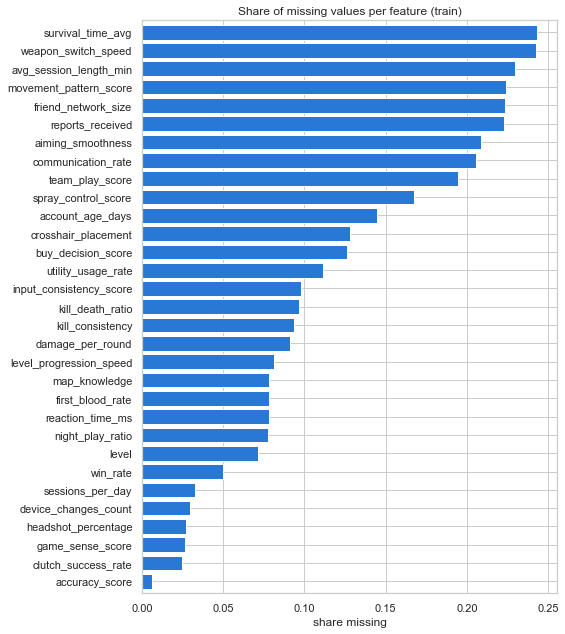

rows with ≥1 NaN: 0.982


In [3]:
na = train[FEATS].isna().mean().sort_values()
ax = na.plot.barh(figsize=(8, 9), color='#2a78d6', width=.8)
ax.set_title('Share of missing values per feature (train)'); ax.set_xlabel('share missing'); plt.tight_layout(); plt.show()
print('rows with ≥1 NaN:', round(float(train[FEATS].isna().any(axis=1).mean()), 3))

In [4]:
# Is missingness informative? Compare the cheater rate when a feature is NaN vs present
lab = train[train[TARGET].notna()]
na_eff = pd.Series({c: lab.loc[lab[c].isna(), TARGET].mean() - lab.loc[lab[c].notna(), TARGET].mean() for c in FEATS})
print('Largest |Δ cheat rate| NaN vs not-NaN:', round(float(na_eff.abs().max()), 4))
print('corr(#NaN per row, target):', np.corrcoef(lab[FEATS].isna().sum(axis=1), lab[TARGET])[0, 1].round(4))

Largest |Δ cheat rate| NaN vs not-NaN: 0.0111
corr(#NaN per row, target): 0.0037


**Audit findings**
- About **12.7% of train rows have no label** (`is_cheater` is NaN). We drop them because they can't be used for supervised training.
- Every feature has **about 20–24% missing values**, spread at random (missingness barely changes the cheater rate). LightGBM and HistGB handle NaN natively, so **we don't impute** (imputation adds no signal here).
- No duplicates and no ID overlap between train and test. `player_id` carries no signal (checked below).

## 2. EDA

labelled rows: 90816 | cheater rate: 0.3493
corr(player_id number, target): -0.0027


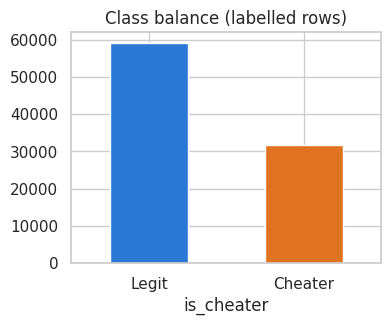

In [5]:
df = train[train[TARGET].notna()].reset_index(drop=True)
df[TARGET] = df[TARGET].astype(int)
y = df[TARGET].values
print('labelled rows:', len(df), '| cheater rate:', round(float(y.mean()), 4))
print('corr(player_id number, target):', np.corrcoef(df[ID].str[1:].astype(int), y)[0, 1].round(4))

ax = df[TARGET].map({0: 'Legit', 1: 'Cheater'}).value_counts().plot.bar(color=[C_LEGIT, C_CHEAT], figsize=(4, 3), rot=0)
ax.set_title('Class balance (labelled rows)'); plt.show()

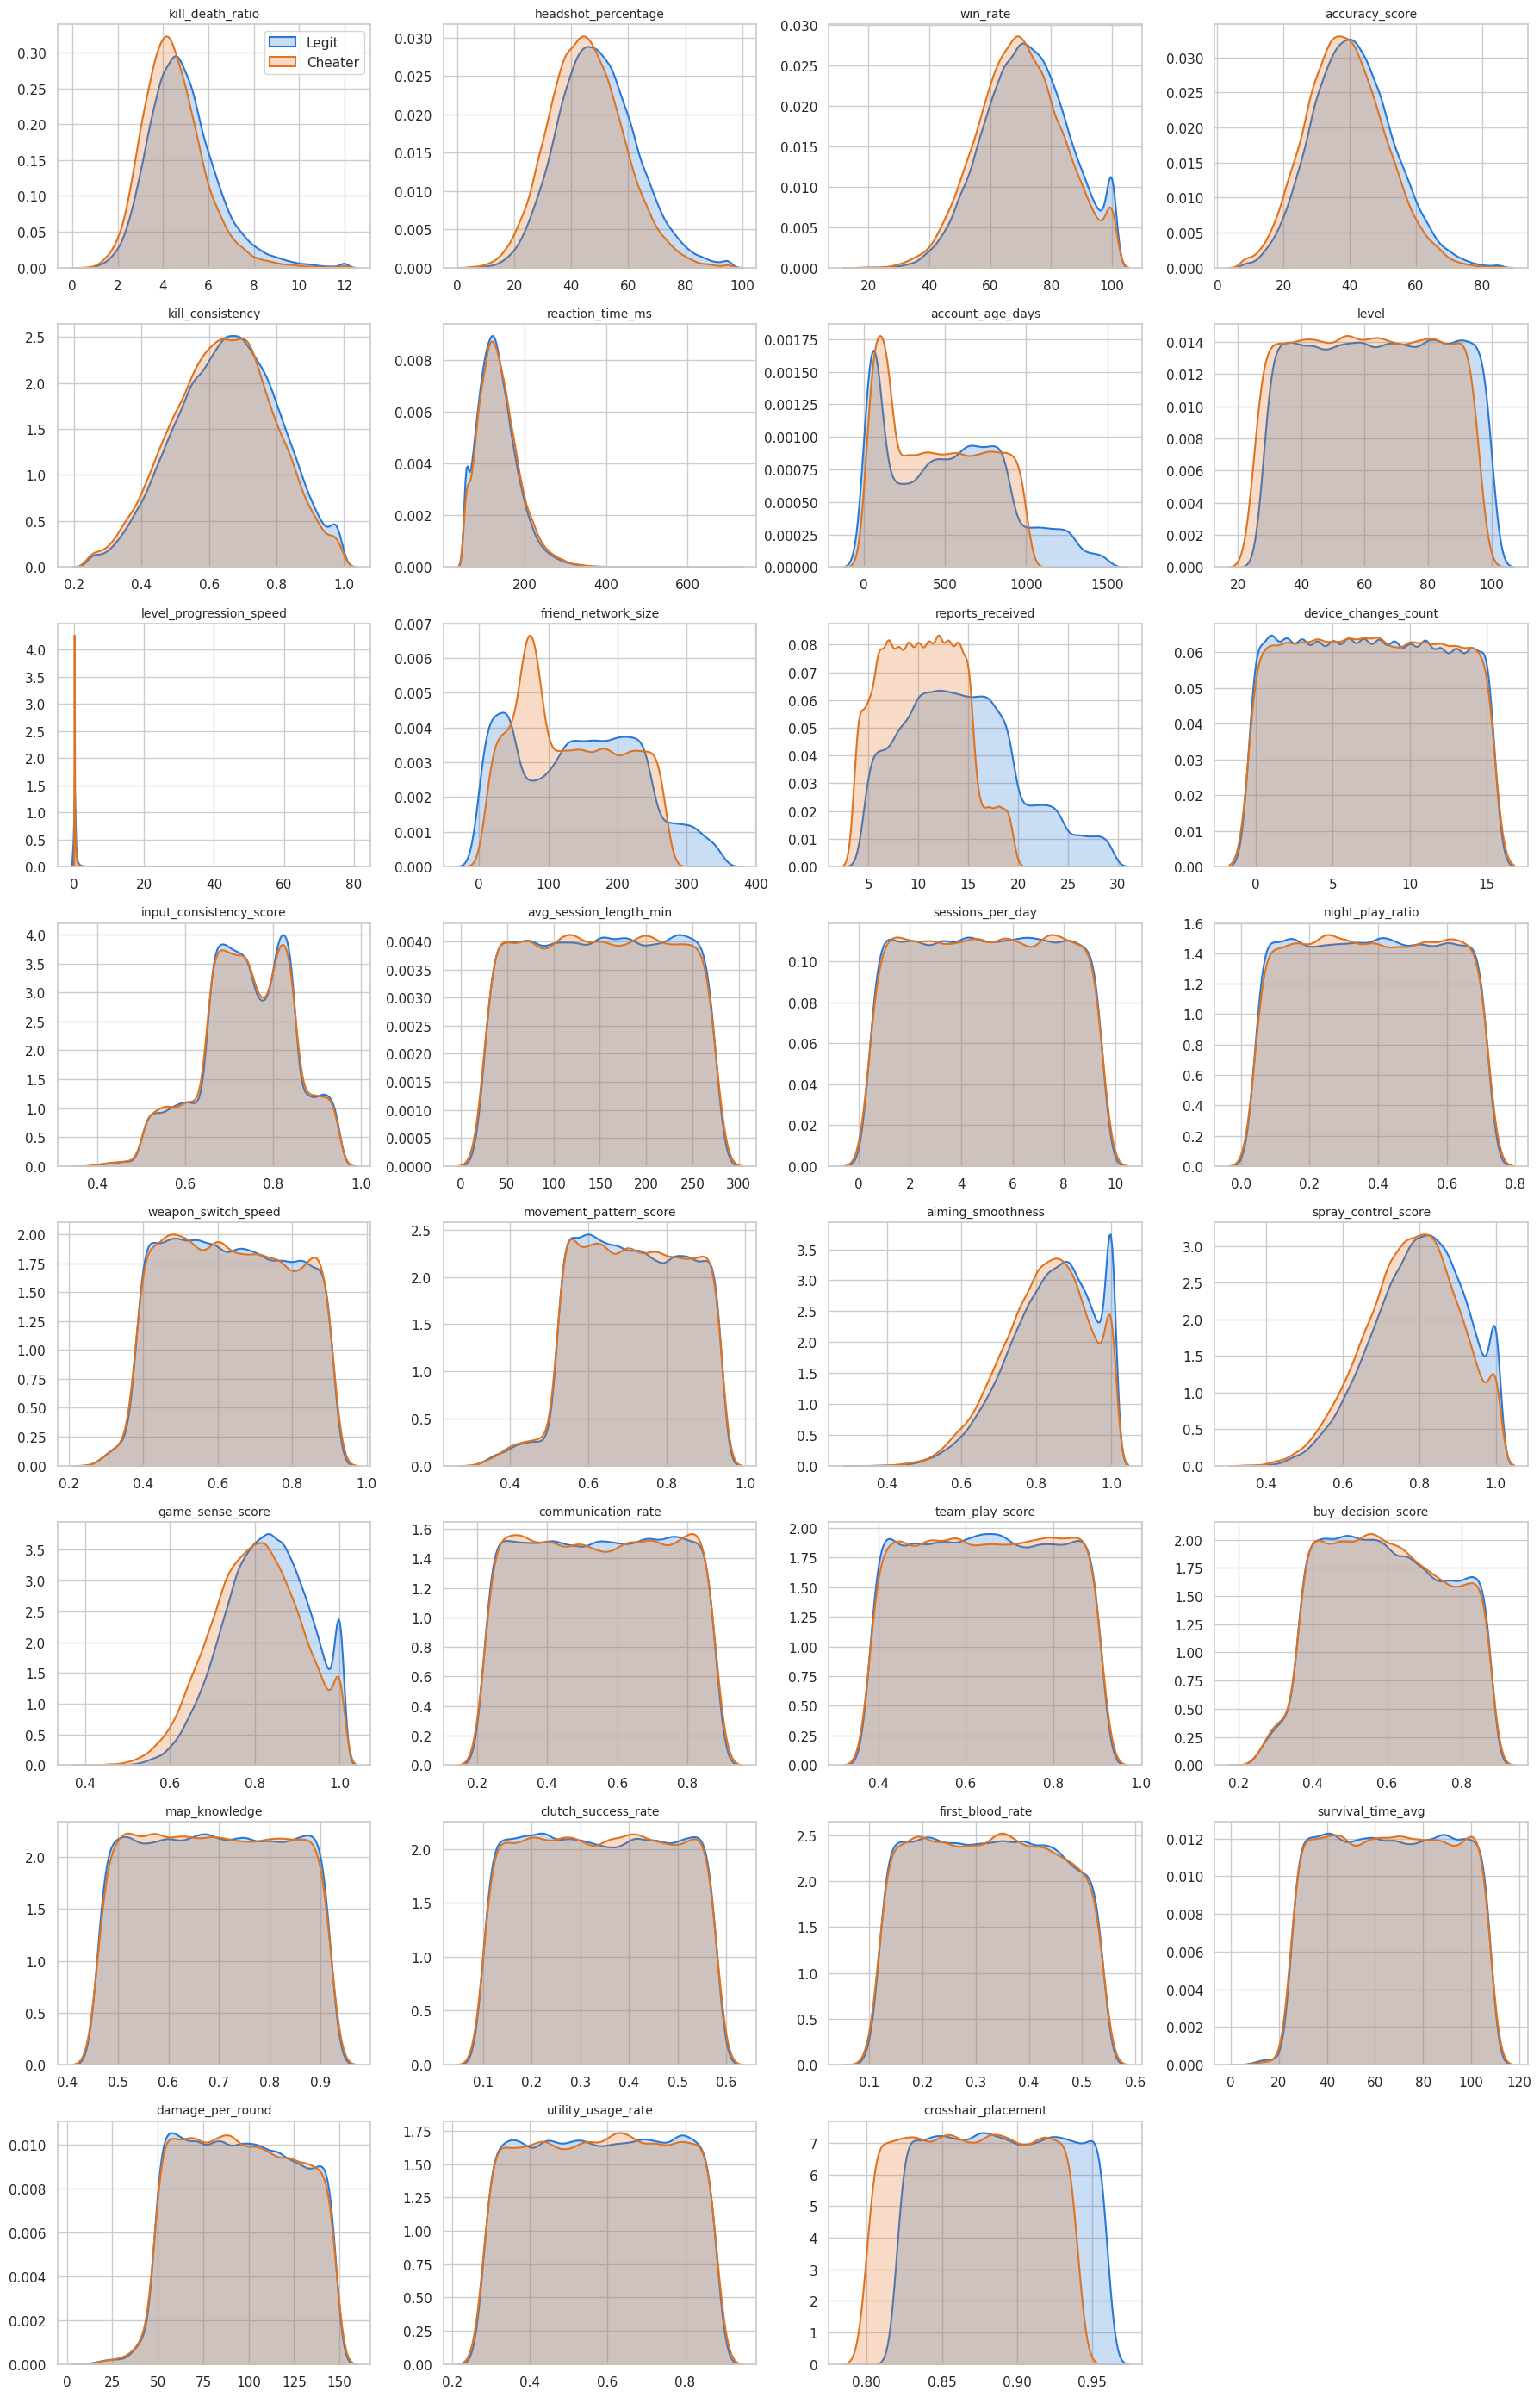

In [6]:
# Distribution of each feature split by class
fig, axes = plt.subplots(8, 4, figsize=(18, 28)); axes = axes.ravel()
for ax, c in zip(axes, FEATS):
    for v, col, lbl in [(0, C_LEGIT, 'Legit'), (1, C_CHEAT, 'Cheater')]:
        sns.kdeplot(df.loc[df[TARGET] == v, c].dropna(), ax=ax, color=col, fill=True, alpha=.25, lw=1.5, label=lbl, common_norm=False)
    ax.set_title(c, fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
axes[0].legend(); [a.axis('off') for a in axes[len(FEATS):]]
plt.tight_layout(); plt.show()

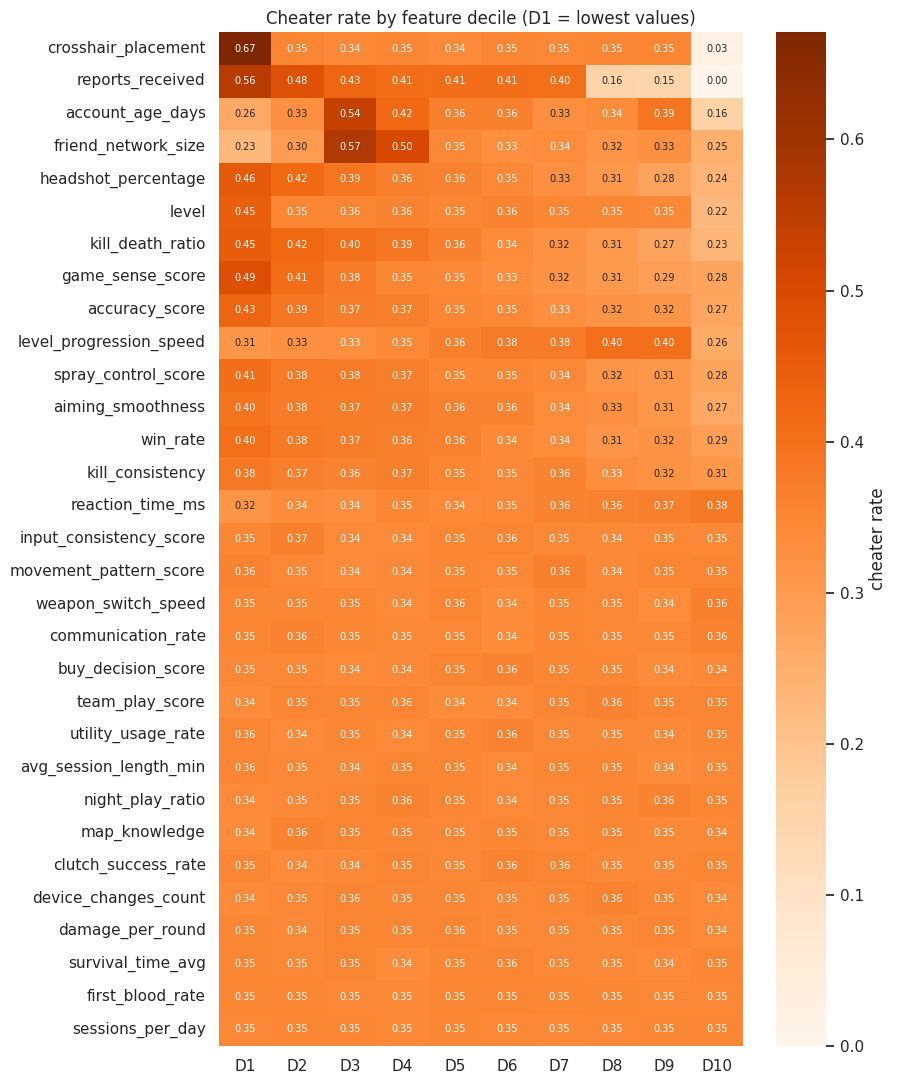

In [7]:
# Most useful view: cheater rate per decile of each feature (exposes non-linear and threshold patterns)
rate = {}
for c in FEATS:
    q = pd.qcut(df[c], 10, duplicates='drop')
    rate[c] = df.groupby(q, observed=True)[TARGET].mean().values
rate_df = pd.DataFrame({c: pd.Series(v) for c, v in rate.items()}).T
rate_df.columns = [f'D{i+1}' for i in range(rate_df.shape[1])]
rate_df = rate_df.loc[(rate_df.max(axis=1) - rate_df.min(axis=1)).sort_values(ascending=False).index]
plt.figure(figsize=(9, 11))
sns.heatmap(rate_df, cmap='Oranges', annot=True, fmt='.2f', cbar_kws={'label': 'cheater rate'}, annot_kws={'size': 7})
plt.title('Cheater rate by feature decile (D1 = lowest values)'); plt.tight_layout(); plt.show()

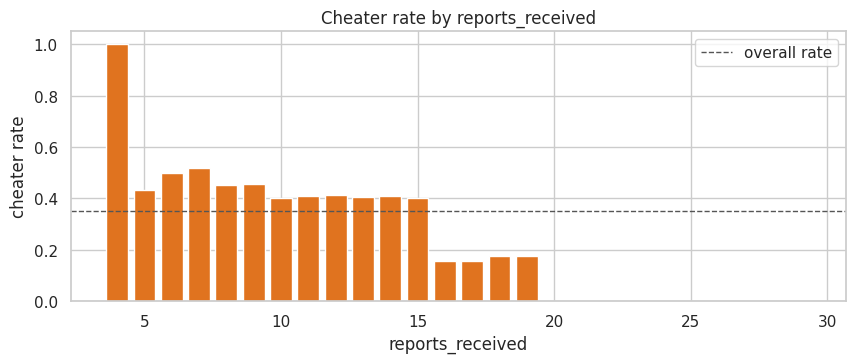

reports_received,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,29.0
mean,1.0,0.43,0.5,0.52,0.45,0.45,0.4,0.41,0.41,0.41,0.41,0.4,0.16,0.16,0.17,0.18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
size,1455.0,3259.00,3887.0,3904.00,4258.00,4376.00,4889.0,4840.00,4993.00,4878.00,4847.00,4683.0,3338.00,3382.00,3055.00,2967.00,1004.0,1003.0,1029.0,1025.0,983.0,475.0,547.0,486.0,522.0,489.0


In [8]:
# reports_received: the most surprising pattern
g = df.groupby('reports_received')[TARGET].agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(g.index, g['mean'], color=C_CHEAT, width=.8)
ax.axhline(y.mean(), color='#555', ls='--', lw=1, label='overall rate'); ax.legend()
ax.set(title='Cheater rate by reports_received', xlabel='reports_received', ylabel='cheater rate'); plt.show()
g.T.round(2)

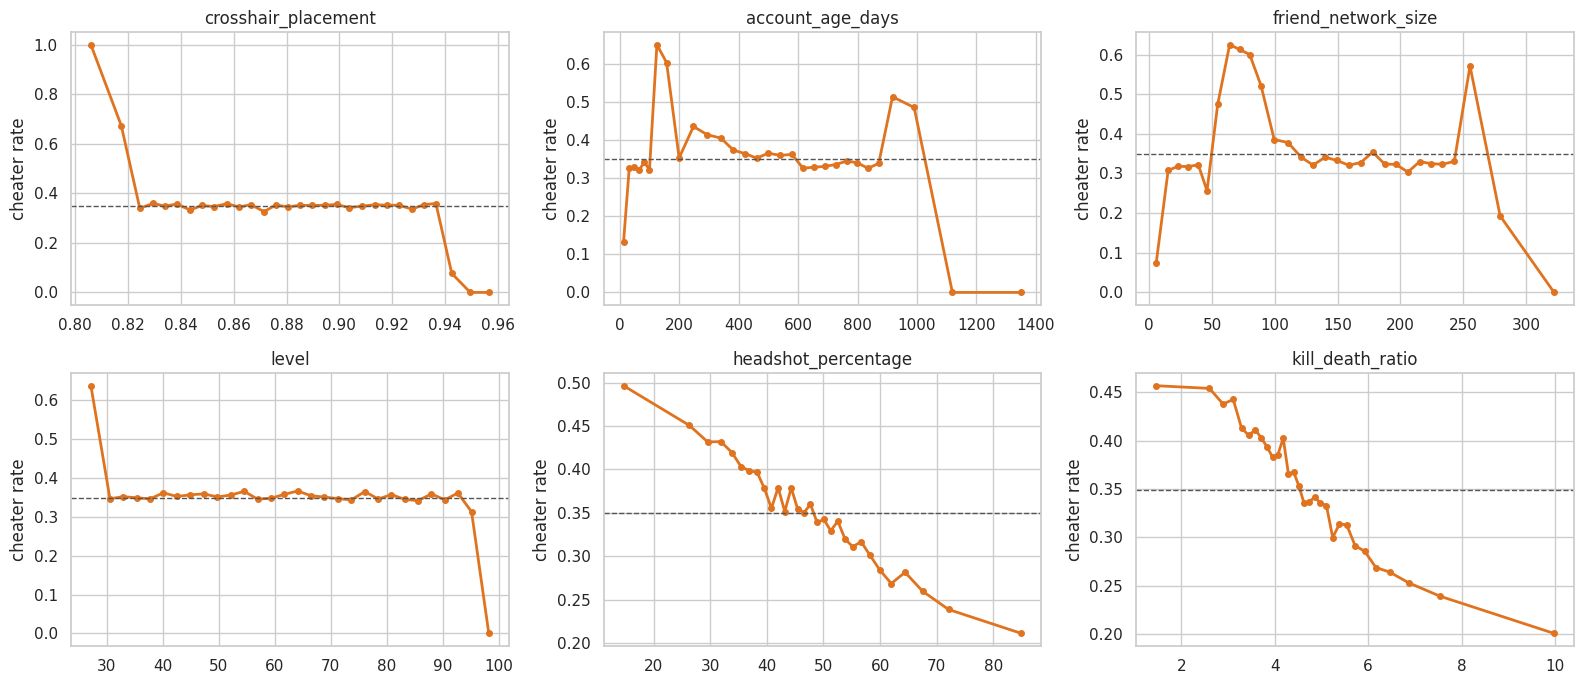

In [9]:
# Key non-linear features: cheater rate across fine bins
key = ['crosshair_placement', 'account_age_days', 'friend_network_size', 'level', 'headshot_percentage', 'kill_death_ratio']
fig, axes = plt.subplots(2, 3, figsize=(16, 7)); axes = axes.ravel()
for ax, c in zip(axes, key):
    q = pd.qcut(df[c], 30, duplicates='drop'); g = df.groupby(q, observed=True)[TARGET].mean()
    ax.plot([i.mid for i in g.index], g.values, color=C_CHEAT, lw=2, marker='o', ms=4)
    ax.axhline(y.mean(), color='#555', ls='--', lw=1); ax.set_title(c); ax.set_ylabel('cheater rate')
plt.tight_layout(); plt.show()

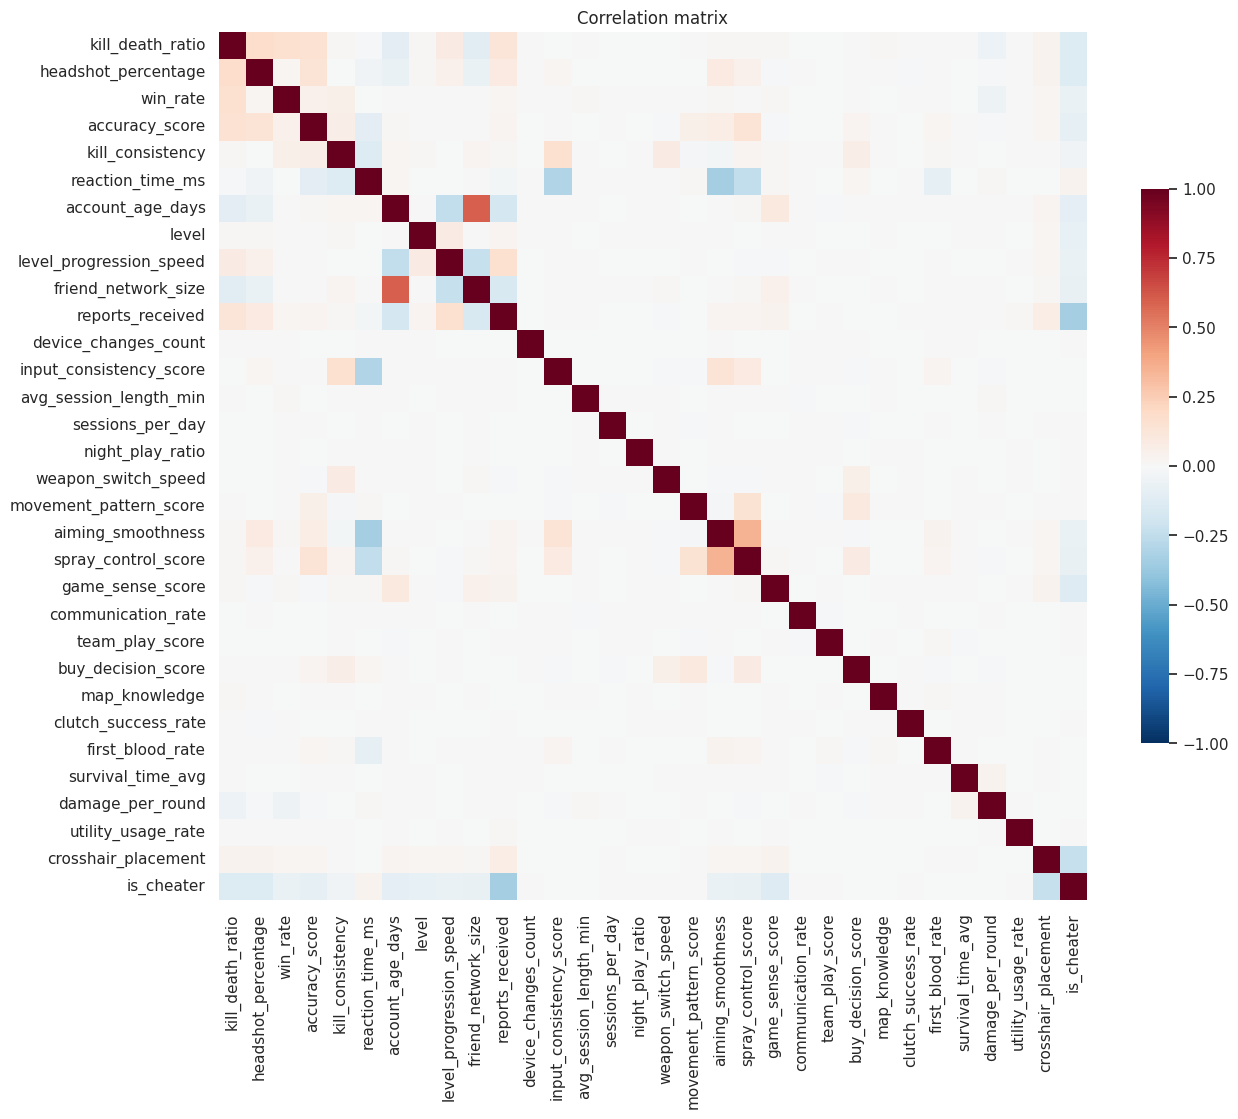

reports_received       0.337
crosshair_placement    0.228
kill_death_ratio       0.134
headshot_percentage    0.133
game_sense_score       0.125
account_age_days       0.098
accuracy_score         0.089
level                  0.082
spray_control_score    0.077
friend_network_size    0.071
Name: is_cheater, dtype: float64


In [10]:
corr = df[FEATS + [TARGET]].corr()
plt.figure(figsize=(14, 12)); sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, cbar_kws={'shrink': .6})
plt.title('Correlation matrix'); plt.show()
print(corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(10).round(3))

### Key insights for the model
1. **The patterns are non-linear and threshold-based.** Linear correlations are weak (max |r| ≈ 0.34), but per-decile cheater rates swing hard. This suits **tree models** best.
2. **`reports_received` is counter-intuitive.** 4 reports means **100% cheaters**; 5–15 sits around 40–50%; 16–19 drops to about 16%; **≥ 20 means 0% cheaters**. Don't assume "more reports = cheater". Let the model learn the cut points.
3. **`crosshair_placement`**: the lowest decile has about 67% cheaters and the highest decile about 3%. The middle is flat.
4. **`account_age_days` and `friend_network_size`** have a peak in deciles 3–4 (around 55%) and low rates at the extremes, so the relationship isn't monotonic.
5. Skill features such as `headshot_percentage`, `kill_death_ratio` and `game_sense_score` **decrease as the cheater rate rises**, which runs against intuition (the data is synthetic).
6. **Missing values are random with respect to the target**, so no missing indicators are needed.
7. `level_progression_speed` correlates with `level / account_age_days` (r ≈ 0.92), so this information is already in the data.

## 3. Feature engineering test
Try ratio and interaction features and check them with CV. **Only keep features that actually improve CV.**

In [13]:
def add_fe(d):
    d = d.copy()
    d['lvl_per_day'] = d.level / d.account_age_days
    d['lps_ratio'] = d.level_progression_speed / d.lvl_per_day
    d['rep_per_day'] = d.reports_received / d.account_age_days
    d['friends_per_lvl'] = d.friend_network_size / d.level
    d['hs_x_acc'] = d.headshot_percentage * d.accuracy_score
    d['kd_x_hs'] = d.kill_death_ratio * d.headshot_percentage
    return d

LGB_FAST = dict(n_estimators=4000, learning_rate=.05, num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.7, verbose=-1)
def quick_cv(X, feats):
    oof = np.zeros(len(X))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(X, y):
        m = lgb.LGBMClassifier(**LGB_FAST).fit(X.loc[a, feats], y[a], eval_set=[(X.loc[b, feats], y[b])],
                                              callbacks=[lgb.early_stopping(150, verbose=False)])
        oof[b] = m.predict_proba(X.loc[b, feats])[:, 1]
    return round(roc_auc_score(y, oof), 5)

dfe = add_fe(df); FE = [c for c in dfe.columns if c not in df.columns]
print('original features AUC', quick_cv(dfe, FEATS))
print('original + all FE  AUC', quick_cv(dfe, FEATS + FE))

original features AUC 0.8905
original + all FE  AUC 0.89004


**Result:** the engineered features **don't help** (the AUC change is within ±0.0005, which is noise). The trees already find the thresholds and ratios themselves, so **we use the original 31 features** to keep the model simple and avoid overfitting.

## 3b. Missing values: model-based imputation + mask augmentation
Every feature has about 20–24% missing values (section 1). Two ideas target this:
1. **Model-based imputation.** For each column, train a LightGBM regressor that predicts it from the other 30 columns and fill its NaNs with the predictions. The target is never used, so the imputer can be fitted on all train rows, including the unlabelled ones (test is never used for training, per the rules). A tree can't recover a missing value itself, but correlated columns can (e.g. `level_progression_speed` ↔ `level / account_age_days`). Columns that the others can't predict (holdout R² < 0.05) stay NaN, because filling them would only add noise.
2. **Mask augmentation.** Train on the training fold **plus a copy of it with extra NaNs**, at a **fixed 10% per column**. The rate is not taken from test, because the rules forbid using test for training. The model learns not to depend on any single column being present.

Both are judged with 5-fold CV on the labelled train rows only; test is never looked at for this decision (competition rule: every setting must be chosen without seeing test).

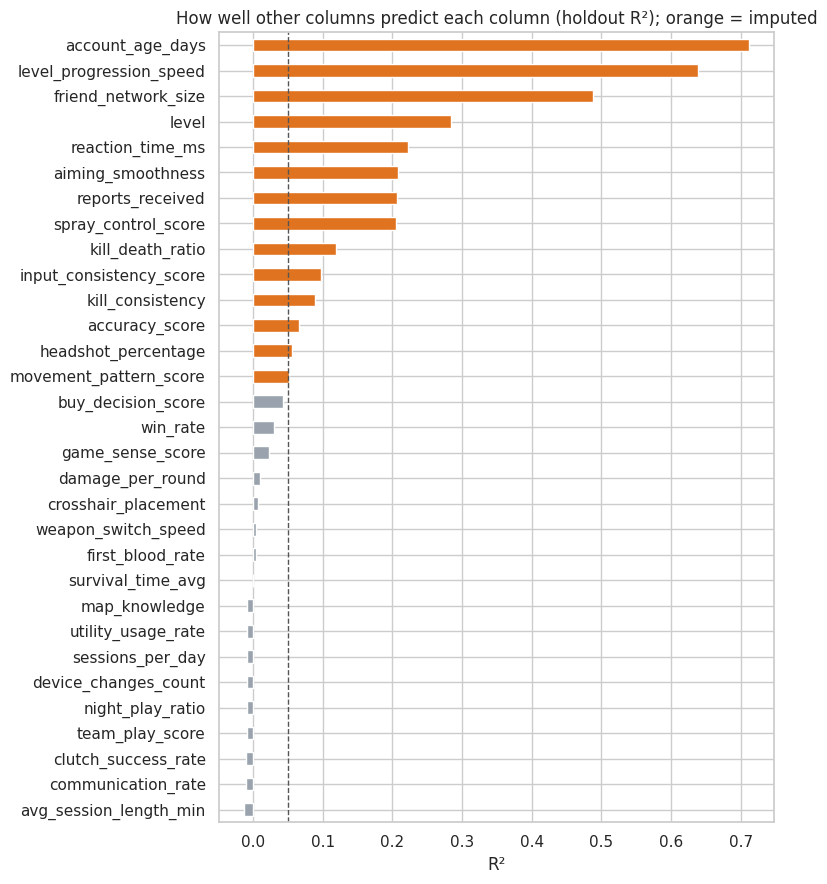

columns imputed: 14 / 31


In [14]:
from sklearn.metrics import r2_score

class ModelImputer:
    # Fill each column's NaN with an LGBM regressor on the other columns (unsupervised: no target used)
    def fit(self, data, min_r2=.05):
        self.models, self.r2, self.min_r2 = {}, {}, min_r2
        for c in FEATS:
            known = data[data[c].notna()]
            others = [f for f in FEATS if f != c]
            hold = np.random.default_rng(SEED).random(len(known)) < .2
            m = lgb.LGBMRegressor(n_estimators=300, learning_rate=.05, num_leaves=63, verbose=-1)
            m.fit(known.loc[~hold, others], known.loc[~hold, c])
            self.r2[c] = r2_score(known.loc[hold, c], m.predict(known.loc[hold, others]))
            self.models[c] = m
        return self

    def transform(self, data):
        out = data.copy()
        for c, m in self.models.items():
            na = data[c].isna()
            if na.any() and self.r2[c] >= self.min_r2:
                out.loc[na, c] = m.predict(data.loc[na, [f for f in FEATS if f != c]])  # inputs = original (unfilled) data
        return out

AUG_EXTRA = pd.Series(.10, index=FEATS)   # fixed extra NaN rate per column; not derived from test (competition rule)
def mask_aug(Xa, seed):
    r, Xm = np.random.default_rng(seed), Xa.copy()
    for c in FEATS: Xm.loc[r.random(len(Xm)) < AUG_EXTRA[c], c] = np.nan
    return Xm

# Final imputer: all train rows (incl. unlabelled), no target
imputer = ModelImputer().fit(train[FEATS])   # train only: competition rules forbid using test for training
r2 = pd.Series(imputer.r2).sort_values()
ax = r2.plot.barh(figsize=(8, 9), color=[C_CHEAT if v >= imputer.min_r2 else '#9aa3ad' for v in r2])
ax.axvline(imputer.min_r2, color='#555', ls='--', lw=1)
ax.set(title='How well other columns predict each column (holdout R²); orange = imputed', xlabel='R²')
plt.tight_layout(); plt.show()
print('columns imputed:', (r2 >= imputer.min_r2).sum(), '/', len(FEATS))

In [15]:
# Experiment on labelled data (train only, no test statistics): native NaN vs imputed, with/without mask augmentation
def exp_cv(X_raw, imp=None, aug=False):
    X_in = imp.transform(X_raw) if imp else X_raw
    oof = np.zeros(len(X_raw))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(X_raw, y):
        xa, ya = X_in.iloc[a], y[a]
        if aug:
            xm = mask_aug(X_raw.iloc[a], SEED)
            xa, ya = pd.concat([xa, imp.transform(xm) if imp else xm]), np.r_[ya, ya]
        m = lgb.LGBMClassifier(**LGB_FAST).fit(xa, ya, eval_set=[(X_in.iloc[b], y[b])],
                                              callbacks=[lgb.early_stopping(150, verbose=False)])
        oof[b] = m.predict_proba(X_in.iloc[b])[:, 1]
    return roc_auc_score(y, oof)

X_exp = df[FEATS]
res = {'native': exp_cv(X_exp), 'impute': exp_cv(X_exp, imputer),
       'native+aug': exp_cv(X_exp, aug=True), 'impute+aug': exp_cv(X_exp, imputer, aug=True)}
print(pd.Series(res).round(5).to_string())

# Keep a change only if it beats native NaN by more than noise
best = max(res, key=res.get)
if res[best] - res['native'] < 3e-4: best = 'native'
USE_IMPUTE, USE_MASK_AUG = 'impute' in best, 'aug' in best
print(f'-> chosen: {best} | USE_IMPUTE={USE_IMPUTE}, USE_MASK_AUG={USE_MASK_AUG}  (override here if you want)')

native        0.89050
impute        0.88844
native+aug    0.89096
impute+aug    0.88875
-> chosen: native+aug | USE_IMPUTE=False, USE_MASK_AUG=True  (override here if you want)


## 4. Modeling: LightGBM + HistGradientBoosting + CatBoost (GPU), 5-fold × 3 seeds

In [16]:
N_FOLDS, SEEDS = 5, [42, 7, 2024]
X_raw = df[FEATS]
X, X_te = (imputer.transform(X_raw), imputer.transform(test[FEATS])) if USE_IMPUTE else (X_raw, test[FEATS])
print(f'USE_IMPUTE={USE_IMPUTE}, USE_MASK_AUG={USE_MASK_AUG}')
LGB_PARAMS = dict(n_estimators=10000, learning_rate=.02, num_leaves=31, min_child_samples=40,
                  subsample=.8, subsample_freq=1, colsample_bytree=.6, reg_lambda=2, verbose=-1)

def run_cv(make_fit, aug=False):
    oof, pred = np.zeros(len(X)), np.zeros(len(X_te))
    for s in SEEDS:
        for a, b in StratifiedKFold(N_FOLDS, shuffle=True, random_state=s).split(X, y):
            xa, ya = X.iloc[a], y[a]
            if aug:  # add a masked copy of the training fold (validation fold stays untouched)
                xm = mask_aug(X_raw.iloc[a], s)
                xa, ya = pd.concat([xa, imputer.transform(xm) if USE_IMPUTE else xm]), np.r_[ya, ya]
            m = make_fit(xa, ya, X.iloc[b], y[b], s)
            oof[b] += m.predict_proba(X.iloc[b])[:, 1] / len(SEEDS)
            pred += m.predict_proba(X_te)[:, 1] / (len(SEEDS) * N_FOLDS)
    return oof, pred

def fit_lgb(xa, ya, xb, yb, s):
    return lgb.LGBMClassifier(**LGB_PARAMS, random_state=s).fit(
        xa, ya, eval_set=[(xb, yb)], callbacks=[lgb.early_stopping(200, verbose=False)])

def fit_hgb(xa, ya, xb, yb, s):
    return HistGradientBoostingClassifier(max_iter=2000, learning_rate=.04, max_leaf_nodes=31, min_samples_leaf=40,
                                          l2_regularization=1., early_stopping=True, validation_fraction=.1,
                                          n_iter_no_change=100, random_state=s).fit(xa, ya)

USE_IMPUTE=False, USE_MASK_AUG=True


### Hyperparameter tuning (Optuna)
Optuna's TPE sampler searches LightGBM's tree parameters (leaves, minimum leaf size, row/column subsampling, L1/L2 regularisation). Each trial is scored by **3-fold OOF AUC** with a faster learning rate (0.05); AUC is the quantity the blend is built on and is smoother than F2 at a tuned threshold. Trial 0 is the hand-set parameters, so the tuned set is only used if it beats them. The final models keep the slower learning rate (0.02) with early stopping.

In [17]:
import os, json, optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNE_KEYS = ('num_leaves', 'min_child_samples', 'colsample_bytree', 'subsample', 'reg_lambda', 'reg_alpha')
SPACE = lambda t: dict(num_leaves=t.suggest_int('num_leaves', 15, 127, log=True),
                       min_child_samples=t.suggest_int('min_child_samples', 10, 200, log=True),
                       colsample_bytree=t.suggest_float('colsample_bytree', .3, 1.),
                       subsample=t.suggest_float('subsample', .5, 1.),
                       reg_lambda=t.suggest_float('reg_lambda', 1e-3, 30, log=True),
                       reg_alpha=t.suggest_float('reg_alpha', 1e-3, 10, log=True))

def tune(name, score, hand, n_trials=40, timeout=20 * 60):
    # Optuna TPE search of LightGBM tree parameters (higher score = better). Trial 0 is the hand-set values,
    # so the result is never worse on this CV. Saved to <name>.json and reused on later runs (delete it to search again).
    path = f'{name}.json'
    if not os.path.exists(path):   # on Kaggle: saved parameters attached as a dataset
        path = next(iter(glob.glob(f'/kaggle/input/**/{name}.json', recursive=True)), path)
    if os.path.exists(path):
        r = json.load(open(path))
        print(f"{name}: loaded {path} | hand-set {r['hand_score']:.5f} -> best {r['best_score']:.5f} after {r['trials']} trials")
        return {**hand, **r['params']}
    start = {k: hand.get(k, 1e-3) for k in TUNE_KEYS}
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42, multivariate=True))
    study.enqueue_trial(start)
    study.optimize(lambda t: score({**hand, **SPACE(t)}), n_trials=n_trials, timeout=timeout)
    h, b = study.trials[0].value, study.best_value
    params = study.best_params if b > h else start
    json.dump({'params': params, 'hand_score': h, 'best_score': b, 'trials': len(study.trials)}, open(path, 'w'), indent=1)
    print(f'{name}: {len(study.trials)} trials | hand-set {h:.5f} -> best {b:.5f} ({b - h:+.5f})',
          '| tuned parameters used' if b > h else '| hand-set parameters kept')
    print('   chosen:', pd.Series(params, dtype=object).to_string().replace(chr(10), ' | '))
    return {**hand, **params}

def score_t1(params):
    oof = np.zeros(len(X))
    for a, b in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X, y):
        m = lgb.LGBMClassifier(**{**params, 'learning_rate': .05}, random_state=SEED).fit(
            X.iloc[a], y[a], eval_set=[(X.iloc[b], y[b])], callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[b] = m.predict_proba(X.iloc[b])[:, 1]
    return roc_auc_score(y, oof)

LGB_PARAMS = tune('task1_lgb_params', score_t1, LGB_PARAMS)

task1_lgb_params: 40 trials | hand-set 0.89048 -> best 0.89115 (+0.00067) | tuned parameters used
   chosen: num_leaves                 39 | min_child_samples          20 | colsample_bytree     0.605133 | subsample            0.890383 | reg_lambda           3.276051 | reg_alpha            0.011039


In [18]:
oof_lgb, pred_lgb = run_cv(fit_lgb, aug=USE_MASK_AUG); print('LightGBM OOF AUC:', round(roc_auc_score(y, oof_lgb), 5))
# HGB gets no augmentation: its internal validation split would contain masked copies of its own training rows
oof_hgb, pred_hgb = run_cv(fit_hgb); print('HistGB   OOF AUC:', round(roc_auc_score(y, oof_hgb), 5))

LightGBM OOF AUC: 0.8926
HistGB   OOF AUC: 0.89216


### CatBoost on GPU
CatBoost alone scores slightly below LightGBM, but its predictions are the least correlated with the other models (r ≈ 0.99 vs 0.996), so it helps the blend.
Tested but **not used**: XGBoost (OOF AUC 0.8915, blend weight ≈ 0). CatBoost keeps hand-set parameters: an earlier 25-minute Optuna run did not beat them.

In [19]:
from catboost import CatBoostClassifier
from catboost.utils import get_gpu_device_count
CAT_DEVICE = 'GPU' if get_gpu_device_count() > 0 else 'CPU'
print('CatBoost device:', CAT_DEVICE)

def fit_cat(xa, ya, xb, yb, s):
    return CatBoostClassifier(iterations=8000, learning_rate=.04, depth=6, l2_leaf_reg=3, border_count=254,
                              task_type=CAT_DEVICE, eval_metric='AUC', od_type='Iter', od_wait=300,
                              random_seed=s, verbose=0).fit(xa, ya, eval_set=(xb, yb))

oof_cat, pred_cat = run_cv(fit_cat, aug=USE_MASK_AUG); print('CatBoost OOF AUC:', round(roc_auc_score(y, oof_cat), 5))
print(pd.DataFrame({'lgb': oof_lgb, 'hgb': oof_hgb, 'cat': oof_cat}).corr().round(4))

CatBoost device: GPU


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric perio

CatBoost OOF AUC: 0.89078
        lgb     hgb     cat
lgb  1.0000  0.9957  0.9891
hgb  0.9957  1.0000  0.9876
cat  0.9891  0.9876  1.0000


In [20]:
# Blend in logit space; weights optimized on OOF AUC
from scipy.optimize import minimize
from scipy.special import logit, expit
names = ['lgb', 'hgb', 'cat']
O = logit(np.clip(np.column_stack([oof_lgb, oof_hgb, oof_cat]), 1e-6, 1 - 1e-6))
Pt = logit(np.clip(np.column_stack([pred_lgb, pred_hgb, pred_cat]), 1e-6, 1 - 1e-6))
norm = lambda w: np.abs(w) / np.abs(w).sum()
res = minimize(lambda w: -roc_auc_score(y, O @ norm(w)), np.ones(3) / 3, method='Nelder-Mead')
W = norm(res.x)
oof, pred = expit(O @ W), expit(Pt @ W)   # back to probability scale for thresholding
print('weights:', dict(zip(names, W.round(3))), '| blend OOF AUC:', round(roc_auc_score(y, oof), 5))

weights: {'lgb': np.float64(0.456), 'hgb': np.float64(0.294), 'cat': np.float64(0.25)} | blend OOF AUC: 0.89307


## 5. Threshold tuning for F2
The competition metric is **F2 = 5·P·R / (4P + R)**, which weights recall 4× more than precision (missing a cheater costs more than an extra manual review). So the best threshold is well below 0.5; we find it on OOF.

F2: best=0.8376 @ t=0.175  (vs F2@0.5=0.6284)
at that threshold: precision=0.531  recall=0.979  F1=0.6885


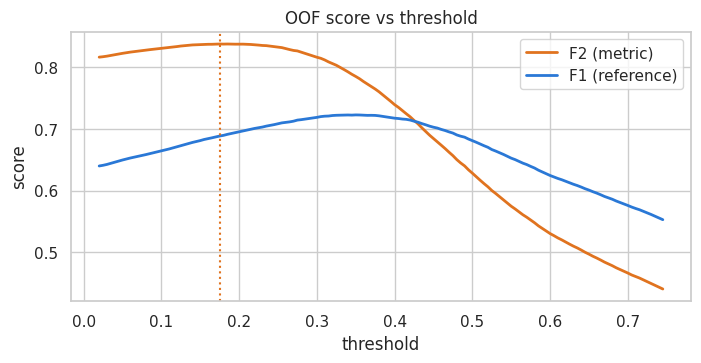

[[31658 27433]
 [  667 31058]]


In [21]:
ths = np.arange(.02, .75, .005)
f2s = np.array([fbeta_score(y, oof >= t, beta=2) for t in ths])
f1s = np.array([f1_score(y, oof >= t) for t in ths])
T_F2 = ths[f2s.argmax()]
print(f'F2: best={f2s.max():.4f} @ t={T_F2:.3f}  (vs F2@0.5={fbeta_score(y, oof >= .5, beta=2):.4f})')
print(f'at that threshold: precision={(y[oof >= T_F2]).mean():.3f}  recall={(oof[y == 1] >= T_F2).mean():.3f}  F1={f1_score(y, oof >= T_F2):.4f}')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ths, f2s, color=C_CHEAT, lw=2, label='F2 (metric)'); ax.plot(ths, f1s, color=C_LEGIT, lw=2, label='F1 (reference)')
ax.axvline(T_F2, color=C_CHEAT, ls=':')
ax.set(xlabel='threshold', ylabel='score', title='OOF score vs threshold'); ax.legend(); plt.show()
print(confusion_matrix(y, oof >= T_F2))

## 6. Feature importance

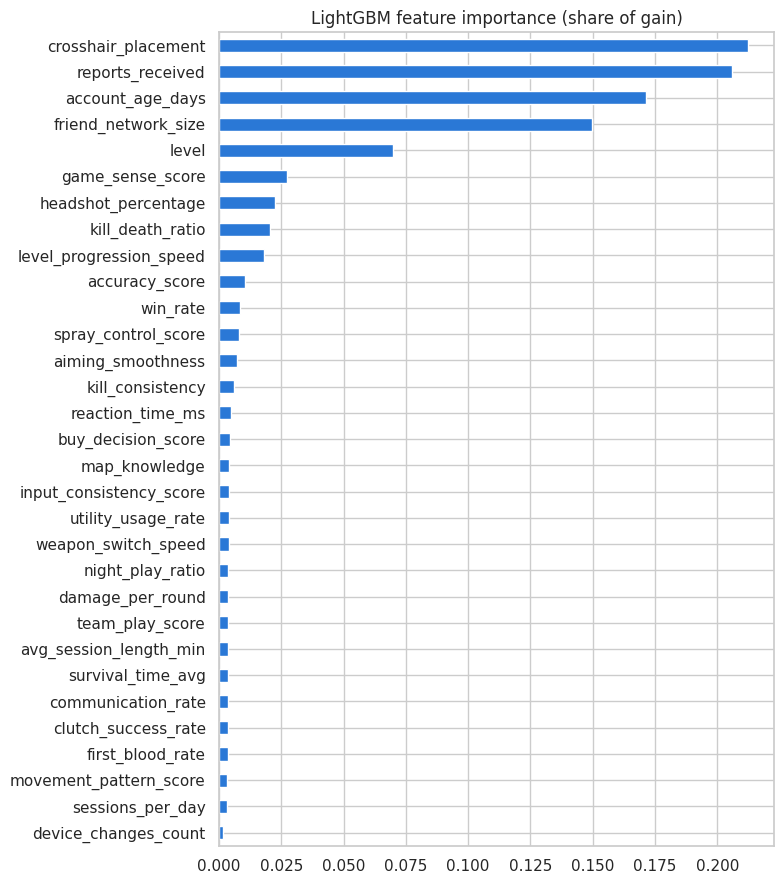

In [22]:
m_full = lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': 800}, random_state=SEED).fit(X, y)
imp = pd.Series(m_full.booster_.feature_importance('gain'), FEATS).sort_values()
ax = (imp / imp.sum()).plot.barh(figsize=(8, 9), color=C_LEGIT)
ax.set_title('LightGBM feature importance (share of gain)'); plt.tight_layout(); plt.show()

The top features are `crosshair_placement`, `reports_received`, `account_age_days` and `friend_network_size`, which matches the EDA (all show strong threshold patterns).

## 7. Submission

In [23]:
import os
T = T_F2
labels = (pred >= T).astype(int)
print(f'threshold={T:.3f} | predicted cheater rate on test={labels.mean():.4f} (train rate={y.mean():.4f})')

# Per-task file (player_id-based)
pd.DataFrame({ID: test[ID], TARGET: labels}).to_csv(f'{OUT_DIR}/submission_task1.csv', index=False)

# Full submission: locally ../submission.csv; on Kaggle our best submission.csv if it is attached as a dataset,
# otherwise the competition's sample_submission.csv (then only this task's column is real)
if ON_KAGGLE:
    full = glob.glob('/kaggle/input/**/submission.csv', recursive=True)
    SUB = full[0] if full else glob.glob('/kaggle/input/**/sample_submission.csv', recursive=True)[0]
    OUT = f'{OUT_DIR}/submission.csv'
else:
    SUB = '../submission.csv' if os.path.exists('../submission.csv') else '../sample_submission.csv'
    OUT = '../submission.csv'
sub = pd.read_csv(SUB)
assert len(sub) == len(test), 'row count mismatch'
sub['task1'] = labels   # assumes row i of the submission = row i of test.csv
sub.to_csv(OUT, index=False)
print(f'updated {OUT} from {SUB}'); display(sub.head())

threshold=0.175 | predicted cheater rate on test=0.6096 (train rate=0.3493)
updated /kaggle/working/submission.csv from /kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/sample_submission.csv


,id,task1,task2,task3,task4,task5
0,ANS00001,1,2.0,2983.20,0.0,1.0
1,ANS00002,1,1.0,529.00,1.0,1.0
2,ANS00003,1,3.0,15682.45,2.0,0.0
3,ANS00004,1,2.0,7200.00,0.0,1.0
4,ANS00005,0,NaN,NaN,NaN,NaN


### Summary
- CV: **3-model blend OOF AUC ≈ 0.893**, with the threshold tuned for the competition metric **F2** (see section 5). Threshold tuning is the biggest single gain in the pipeline.
- Engineered features and missing indicators **gave no gain**. The data looks synthetic with threshold rules plus noise, so the score is near its noise ceiling.
- Missing values: section 3b tests model-based imputation and mask augmentation on train-only CV and switches them on only when they beat the plain setup (mask augmentation won, see `USE_IMPUTE` / `USE_MASK_AUG`).
- Test data is never used for training (competition rule): no pseudo-labelling on test, and the imputer is fitted on train only.